## Вариант 1
Методом моментов найти оценку параметра $\theta$ равномерного, распределения на $[-\theta, \theta]$. Эксперимент при $\theta = 10$.

### Метод моментов
$X_1, X_2, ..., X_n \sim U[-\theta, \theta], \theta > 0$. Вместо $\theta$, оценим параметр $\theta^2$ 

Первый момент величины $X^2$:
$$p(x) = \frac1{2\theta} \bold{1}(|x|\le\theta)$$
$$EX^2 = \int_{-\theta}^{\theta} x^2 * p(x) dx = \frac{\theta^2}3$$

Посчитаем также второй момент $X^2$: $ EX^4 = \frac{\theta^4}5 $ 

Итоговая оценка: $\hat{\theta^2} = 3*\overline{X^2}$

### Свойства оценки

$E[\widehat{\theta^2}]=\frac3n\sum_{i=1}^nE[X_i^2]=\theta^2$ - оценка несмещена

$Bias(\widehat{\theta^2}) = 0$, поэтому

$MSE(\widehat{\theta^2}) = Var(\widehat{\theta^2}) = \frac{9}n (\frac{\theta^4}5 - \frac{\theta^4}{9}) = \frac{4\theta^4}{5n}$

По закону больших чисел $\widehat{\theta^2} = 3\overline{X^2} \rightarrow \theta^2$ - оценка состоятельна

По ЦПТ $\sqrt{n}(\widehat{\theta^2} - \theta^2) \xrightarrow{d} N(0, \frac{4\theta^4}5)$ - асимптотическая нормальность


    n        mean         var        bias         mse   count   fraction
------------------------------------------------------------------------
   10   99.724276  811.786662   -0.275724  811.862686     848     0.8480
   50   99.711395  168.358993   -0.288605  168.442286     696     0.6960
  100  100.328705   79.257156    0.328705   79.365203     563     0.5630
  500   99.934673   15.525366   -0.065327   15.529634     193     0.1930
 1000   99.953518    8.701858   -0.046482    8.704018      89     0.0890
 5000  100.043291    1.609117    0.043291    1.610991       0     0.0000
10000   99.945435    0.747332   -0.054565    0.750309       0     0.0000
50000   99.986970    0.167739   -0.013030    0.167909       0     0.0000


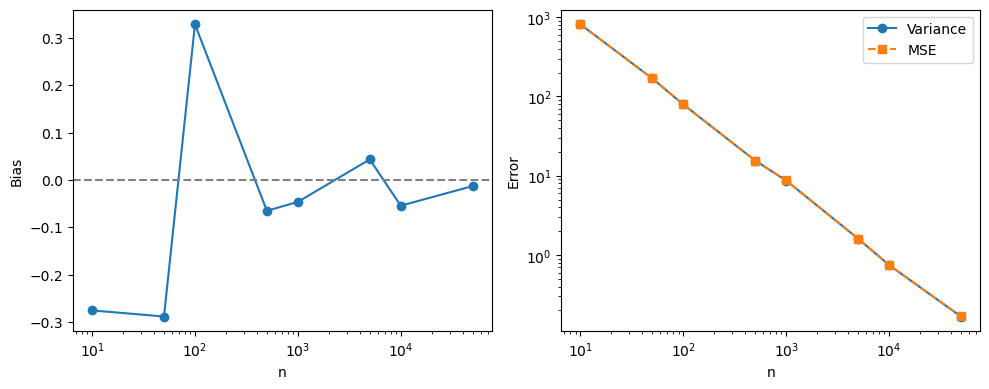

In [81]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(6767)

sizes = [10, 50, 100, 500, 1000, 5000, 10000, 50000]
m = 1000
theta = 10
eps = 5 # threshold

biases, varianses, mses = [], [], []

print(f"{'n':>5} {'mean':>11} {'var':>11} {'bias':>11} {'mse':>11} {'count':>7} {'fraction':>10}")
print("-"*72)
for n in sizes:
    samples = rng.uniform(-theta, theta, (m, n))
    est = 3 * (samples**2).mean(axis=1)
    errors = est - theta**2
    count = np.count_nonzero(np.abs(errors) > eps)
    fraction = count / m
    bias = errors.mean()
    var = est.var()
    mse = np.mean(errors**2)
    biases.append(bias)
    varianses.append(var)
    mses.append(mse)

    print(f"{n:5d} {est.mean():11.6f} {var:11.6f} {bias:11.6f} {mse:11.6f} {count:7d} {fraction:10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].semilogx(sizes, biases, "o-")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(xlabel="n", ylabel="Bias")

axes[1].loglog(sizes, varianses, "o-", label="Variance")
axes[1].loglog(sizes, mses, "s--", label="MSE")
axes[1].set(xlabel="n", ylabel="Error")
axes[1].legend()

plt.tight_layout()
plt.show()


### Интерпретация результатов

Из результатов эксперимента видно, что среднее оценок $\verb|mean|$ находится около $100$, что согласуется с несмещенностью оценки. Теоретическое смещение равно 0 при любом $n$. Эмпирическое смещение колеблется около нуля из-за конечного числа повторений. Теоретические $\verb|Var|$ и $\verb|MSE|$ совпадают и равны $8000/n$. Эмпирический $\verb|Var|$ близок к $\verb|MSE|$ и они оба стремятся к 0. Количество выборок $\verb|count|$, ошибка которых превышает выбранный порог $\verb|eps| = 5$, а также их доля $\verb|fraction|$ уменьшаются с увеличением $n$. 